Epoch 1/20, Loss: 0.9769332077503204
Epoch 2/20, Loss: 0.9498110665678978
Epoch 3/20, Loss: 0.936068968653679
Epoch 4/20, Loss: 0.9275178614258767
Epoch 5/20, Loss: 0.9215836952328682
Epoch 6/20, Loss: 0.9171839657425881
Epoch 7/20, Loss: 0.9137710046768188
Epoch 8/20, Loss: 0.9110442957282067
Epoch 9/20, Loss: 0.9088167726993561
Epoch 10/20, Loss: 0.9069643502831459
Epoch 11/20, Loss: 0.9054052955508232
Epoch 12/20, Loss: 0.9040782381892204
Epoch 13/20, Loss: 0.9029399736523628
Epoch 14/20, Loss: 0.901957014977932
Epoch 15/20, Loss: 0.9011032971739769
Epoch 16/20, Loss: 0.9003584219813346
Epoch 17/20, Loss: 0.8997060278058052
Epoch 18/20, Loss: 0.8991328237056733
Epoch 19/20, Loss: 0.898627524793148
Epoch 20/20, Loss: 0.8981810814738274


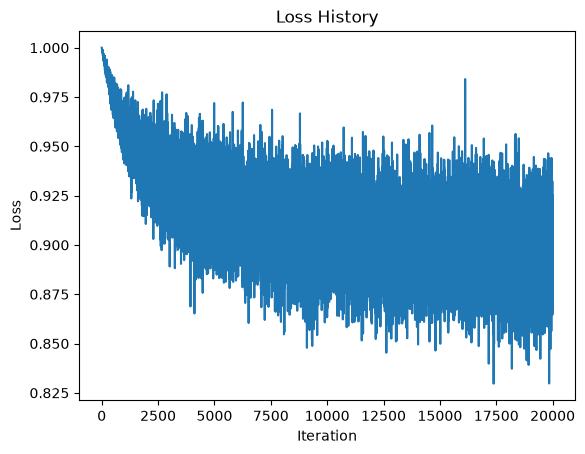

Training accuracy: 32.22%
Test accuracy: 32.42%


In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# 1. Dataloading
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = (torch.randn(Din, K) * std)  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b  # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Epoch 1/10, Loss: 2.0711891919374468
Epoch 2/10, Loss: 1.819261487364769
Epoch 3/10, Loss: 1.7291698914766311
Epoch 4/10, Loss: 1.6786141978502274
Epoch 5/10, Loss: 1.641053901195526
Epoch 6/10, Loss: 1.6091494407653808
Epoch 7/10, Loss: 1.58250422167778
Epoch 8/10, Loss: 1.5585657439231873
Epoch 9/10, Loss: 1.5366098914146424
Epoch 10/10, Loss: 1.5181932312250137


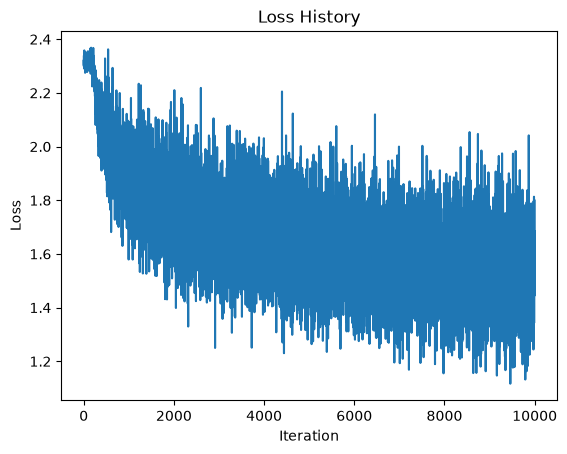

Training accuracy: 48.11%
Test accuracy: 45.82%


In [12]:
# Modified fully connected network with 100 unit hidden layer

# Define the sigmoid activation function
def sigmoid(x):
    return torch.sigmoid(x)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100  # Hidden layer size
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize modified weights and biases
w1 = (torch.randn(Din, H) * std)  # first layer weights ( Din - H)
b1 = torch.zeros(H)
w2 = (torch.randn(H, K) * std)  # second layer weights
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 8e-2  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = (nn.functional.one_hot(labels, K).float())  # Convert labels to one-hot

        # Forward pass
        # Modified using the new hidden layer
        a_1 = x_train.mm(w1) + b1  # First layer activation
        a_1 = sigmoid(a_1)  # Apply sigmoid activation
        y_pred = a_1.mm(w2) + b2  # Output layer activation

        # Loss calculation (Cross entrophy loss) calculated using PyTorch's built-in CrossEntropyLoss function.
        loss = nn.CrossEntropyLoss()(y_pred, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Modified Backpropagation for the two-layer network
        y_pred_probs = torch.softmax(y_pred, dim=1)
        dy_pred =  (y_pred_probs - y_train_onehot) / Ntr

        dw2 = a_1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        # Backpropagate to the hidden layer
        da_1 = dy_pred.mm(w2.t())
        dz_1 = da_1 * (a_1 * (1 - a_1))  # Derivative of sigmoid

        # Compute gradients for the first layer
        dw1 = x_train.t().mm(dz_1) + reg * w1
        db1 = dz_1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_train.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_train_pred = a_1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass
        a_1 = x_test.mm(w1) + b1
        a_1 = sigmoid(a_1)
        y_test_pred = a_1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")